Implement K-Means clustering/ hierarchical clustering on sales_data_sample.csv dataset.  Determine the number of clusters using the elbow method.  Dataset link : https://www.kaggle.com/datasets/kyanyoga/sample-sales-data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

In [2]:
pip install pandas numpy matplotlib scikit-learn scipy

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [3]:
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")

print(df.head())
print(df.shape)

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

In [5]:
data = df[['QUANTITYORDERED', 'PRICEEACH',
           'SALES', 'MSRP']]

data = data.dropna()

print(data.head())

   QUANTITYORDERED  PRICEEACH    SALES  MSRP
0               30      95.70  2871.00    95
1               34      81.35  2765.90    95
2               41      94.74  3884.34    95
3               45      83.26  3746.70    95
4               49     100.00  5205.27    95


In [6]:
scaler = StandardScaler()

scaled_data = scaler.fit_transform(data)

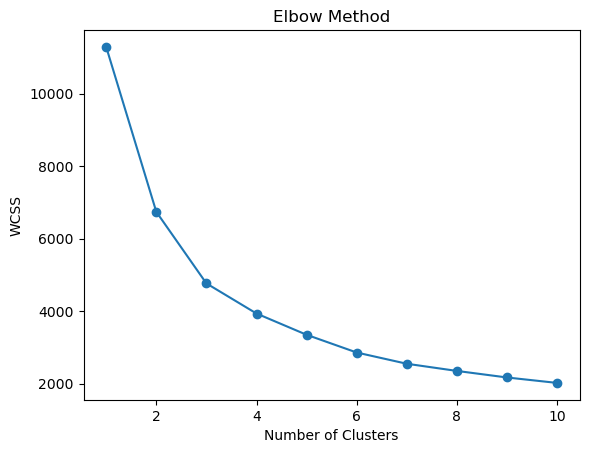

In [7]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(scaled_data)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, marker='o')

plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.show()

In [9]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

data['Cluster'] = kmeans.fit_predict(scaled_data)

print(data.head())

print("\nCluster Counts:")
print(data['Cluster'].value_counts())

   QUANTITYORDERED  PRICEEACH    SALES  MSRP  Cluster
0               30      95.70  2871.00    95        1
1               34      81.35  2765.90    95        1
2               41      94.74  3884.34    95        0
3               45      83.26  3746.70    95        0
4               49     100.00  5205.27    95        2

Cluster Counts:
Cluster
1    930
2    705
3    627
0    561
Name: count, dtype: int64


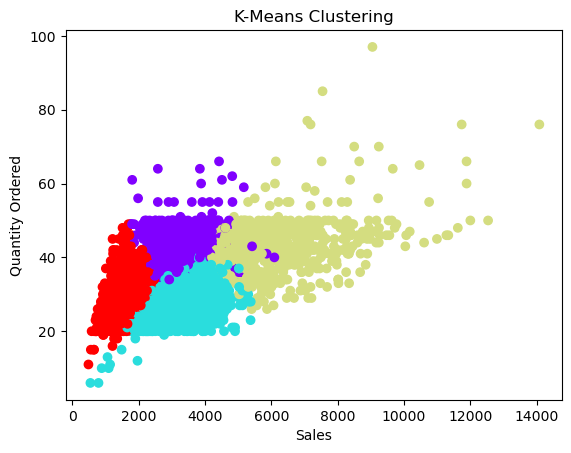

In [10]:
plt.scatter(data['SALES'], data['QUANTITYORDERED'],
            c=data['Cluster'], cmap='rainbow')

plt.title("K-Means Clustering")
plt.xlabel("Sales")
plt.ylabel("Quantity Ordered")
plt.show()

In [11]:
from sklearn.cluster import AgglomerativeClustering

hc = AgglomerativeClustering(
    n_clusters=4,
    linkage='ward'
)

data['Hierarchical_Cluster'] = hc.fit_predict(scaled_data)

print(data.head())

print("\nHierarchical Cluster Counts:")
print(data['Hierarchical_Cluster'].value_counts())

   QUANTITYORDERED  PRICEEACH    SALES  MSRP  Cluster  Hierarchical_Cluster
0               30      95.70  2871.00    95        1                     2
1               34      81.35  2765.90    95        1                     2
2               41      94.74  3884.34    95        0                     3
3               45      83.26  3746.70    95        0                     3
4               49     100.00  5205.27    95        2                     0

Hierarchical Cluster Counts:
Hierarchical_Cluster
0    934
1    742
2    685
3    462
Name: count, dtype: int64


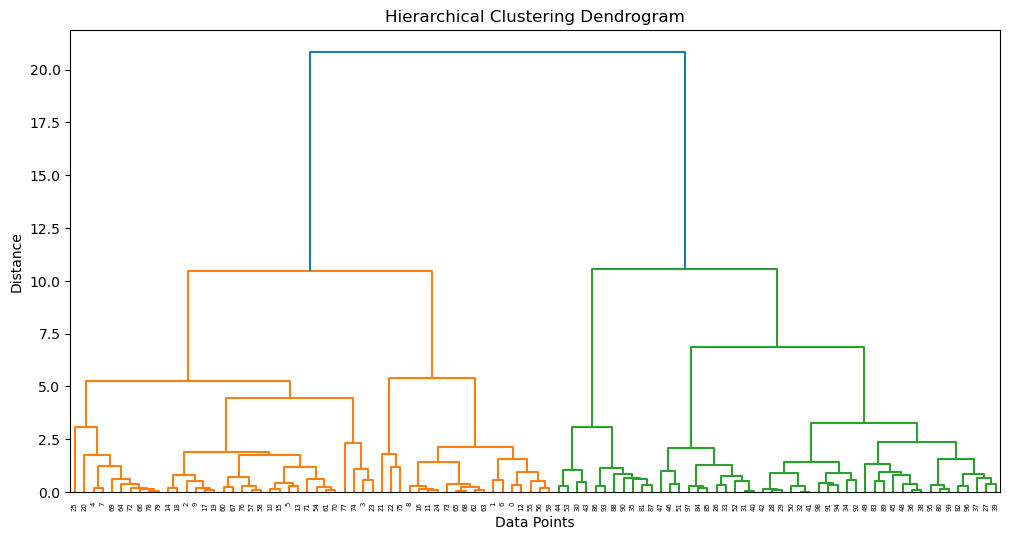

In [12]:
from scipy.cluster.hierarchy import dendrogram, linkage

Z = linkage(scaled_data[:100], method='ward')

plt.figure(figsize=(12, 6))

dendrogram(Z)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")

plt.show()

In [13]:
print("K-Means Clustering:")
print(data['Cluster'].value_counts())

print("\nHierarchical Clustering:")
print(data['Hierarchical_Cluster'].value_counts())

K-Means Clustering:
Cluster
1    930
2    705
3    627
0    561
Name: count, dtype: int64

Hierarchical Clustering:
Hierarchical_Cluster
0    934
1    742
2    685
3    462
Name: count, dtype: int64
